---
title: "Grace's regime map: Geldart's boundaries for any gas, and where his two B/D criteria part"
description: "Grace (1986) extends Geldart's powder groups to any gas in the coordinates d* and U*; the page tests whether every boundary number he prints follows from the correlation and constants he states for it, and measures where his two B/D criteria part."
categories: [sec:E, tier:T1, data:tier0, phase:gas-solid]
date: 2026-11-27
---

# Grace's regime map: Geldart's boundaries for any gas, and where his two B/D criteria part

**Catalog ID:** `E2.3` · **Structures:** none (algebra on printed correlations) · **Tier:** T1

Grace's 1983 ERCO award lecture, published in the *Canadian Journal of Chemical
Engineering* in 1986, puts gas-solid contactors on one map: the dimensionless
superficial velocity $U^*$ against the dimensionless particle diameter $d_p^*$. On
that map he redraws Geldart's powder groups C, A, B and D, which Geldart had drawn
for air at ambient conditions only, as boundaries that hold for any gas: C/A from
Molerus's cohesion balance, A/B from a fit to bubbling data, and B/D twice, once from
the condition that bubbles become slower than the interstitial gas and once from
the balance of the two Ergun terms. This page tests whether every boundary number
he prints follows, within its printed rounding, from the correlation and constants
he states for it, and measures how far his two B/D criteria, both built on the same
minimum-fluidisation correlation with the same constants, lie apart. The paper
carries no reactor model; nothing here is discretised.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "E2.3-grace-regime-map"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is algebra: it calls no pymrm operator and solves no PDE. pymrm
# contributes pymrm.checks.find_roots, which brackets every root the page reports.
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def plain(df):
    """A comparison table as plain strings: a Styler's text repr carries a memory address."""
    return df.assign(computed=[f"{v:.5g}" for v in df["computed"]],
                     **{"half-units": [f"{v:.3f}" for v in df["half-units"]]}).reset_index(drop=True)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

Geldart (1973) sorted powders fluidised by air at ambient conditions into four
groups by mean size and density difference: cohesive C, aeratable A, bubbling B and
spoutable D. His boundaries are dimensional, so they say nothing about another gas,
temperature or pressure. Grace (1986) writes the state of a uniform suspension as a
function of $d_p^*$, $U^*$ and $\Delta\rho/\rho$ only, and places each boundary in
$d_p^*$ as a function of $\Delta\rho/\rho$ at most. The question the paper answers is
where each group ends for any gas; the question this page asks is whether the numbers
he prints for those ends are the ones his own equations give, and how much his two B/D
criteria disagree.

A1.7 owns Geldart's dimensional criteria and the argument that B/D is a cloud
condition; A1.8 owns drag closures and Richardson-Zaki against data. This page uses
Grace's printed numbers only and borrows no dataset.

## The published model

Symbols: $d_p$ particle diameter, $U$ superficial velocity, $\rho$ gas density,
$\Delta\rho = \rho_p - \rho$, $\mu$ gas viscosity, $g$ gravity, $x = \Delta\rho/\rho$.

| eq | as the page uses it | page (PDF) |
|---|---|---|
| 3, 4 | $d_p^* = d_p[\rho g\Delta\rho/\mu^2]^{1/3}$, $U^* = U[\rho^2/(\mu g\Delta\rho)]^{1/3}$ | 354 (2) |
| 5 to 9 | $Ar = d_p^{*3}$, $Re = d_p^*U^*$, $Fr = U^{*2}/d_p^*$, $C_D = 4d_p^*/(3U^{*2})$, $M = U^{*3}$; Clift's $N_D = C_D Re^2 = 4d_p^{*3}/3$ | 354-355 (2-3) |
| 10, 10a | $Re_{mf} = \sqrt{C_1^2 + C_2 Ar} - C_1$, equivalently $Ar = 2(C_1/C_2)Re_{mf} + Re_{mf}^2/C_2$ | 355, 361 (3, 9) |
| 11, 11a, 11b | $U^*_{mf} = Re_{mf}/d_p^*$; limits $0.5C_2 d_p^{*2}/C_1$ ($d_p^* \lesssim 10$) and $\sqrt{C_2 d_p^*}$ ($d_p^* \gtrsim 500$) | 355-356 (3-4) |
| Table 6 | six $(C_1, C_2)$ pairs and the derived columns $C_2/2C_1$, $C_2^{0.5}$, $2(C_1^2/C_2)^{1/3}$ | 358 (6) |
| Table 2 | $v_T^*(d_p^*)$ for spheres in four pieces, adapted from Clift et al. (1978) | 355 (3) |
| 12, 13 | Richardson-Zaki $\epsilon^n = U/v_T$ with $n$ in four brackets of $d_p^*$ "or" $v_T^*$ | 355 (3) |
| 14, 15 | C/A (Molerus): $g\Delta\rho d_p^3 = 0.1KF_H$; for air at 298 K and 101.3 kPa, $(d_p^*)_{CA} \approx$ 0.68 to 1.1, $Ar_{CA}$ = 0.31 to 1.3 | 359 (7) |
| 16, 17 | A/B: $(d_p^*)_{AB} = 101x^{-0.425}$ or $Ar_{AB} = 1.03\times10^6x^{-1.275}$; for $x \approx$ 1000-2000, $(d_p^*)_{AB} \approx 5$ or $Ar_{AB} \approx 125$ | 359 (7) |
| 18, 19 | B/D (cloud): $0.711\sqrt{gd_b} = \mu\{\sqrt{C_1^2 + C_2 d_p^{*3}} - C_1\}/\rho d_p\epsilon_{mf}$; with $d_b = 100d_p$, $\epsilon_{mf} = 0.42$, $C_1 = 27.2$, $C_2 = 0.0408$: $(d_p^*)_{BD} = 251\{(\rho/\Delta\rho)/(1 - 219\rho/\Delta\rho)^2\}^{1/3}$ | 360-361 (8-9) |
| 20, 21 | B/D (Ergun terms equal at $Re_{mf} = 2C_1$): $(d_p^*)_{BD} = 2(C_1^2/C_2)^{1/3}$; with Richardson or Grace $C_1, C_2$: $(d_p^*)_{BD} = 53$ or $Ar_{BD} = 1.45\times10^5$ | 361 (9) |

Eq 18 is typeset over two lines; the division is by the product $\rho d_p\epsilon_{mf}$
(both sides are then m/s). Eq 19 is the page's own re-derivation target: with
$\sqrt{gd_p} = V\sqrt{d_p^*/x}$ and $U_{mf} = V Re_{mf}/d_p^*$, $V = (\mu g\Delta\rho/\rho^2)^{1/3}$,
eq 18 becomes $a\,d_p^{*1.5}x^{-0.5} = Re_{mf}(d_p^*)$ with
$a = 0.711\sqrt{d_b/d_p}\,\epsilon_{mf}$; squaring (both sides positive) gives
$d_p^{*1.5} = 2aC_1x^{-0.5}/(C_2 - a^2/x)$, so eq 19's prefactor is
$(4a^2C_1^2/C_2^2)^{1/3}$ and its constant is $b = a^2/C_2$. For $x \le b$,
$(a^2/x - C_2)d_p^{*3} + 2aC_1x^{-0.5}d_p^{*1.5} > 0$ for every $d_p^*$: eq 18 has no
root, which is the paper's sentence about high pressure. The crossing of eq 19 with a
constant $d_0$ solves $q(1 - b/x)^2 = 1/x$, $q = (d_0/\text{prefactor})^3$, a quadratic in
$1/x$ of which the root with $b/x < 1$ is kept. The ratio of eq 19 to eq 16 has
$d\ln/dx = 0$ where $(0.425 - 1/3)(x - b) = (2/3)b$.

Grace's own words on the two B/D criteria: eq 19 "which is valid only for
$\Delta\rho/\rho$ > 219. (For smaller $\Delta\rho/\rho$ values $u_b$ always exceeds
$U_{mf}/\epsilon_{mf}$ implying that group D behaviour will never be achieved in
fluidized beds operated at high pressure.)" and "For most low pressure systems of
practical importance, $\Delta\rho/\rho$ is of order 500 to $10^4$ giving corresponding
($d_p^*$) limits of 46 to 12." Of eq 21: "This equation is recommended since it has two
complementary physical interpretations, as discussed above, and it provides an
excellent separation between available data points for the two powder groups."

## Parameters and assumptions

Every constant of the paper comes from `data/grace-1986-printed-numbers.csv` as a
string, so that each printed number can be compared in half-units of its own last
printed digit (a value rounds to the printed entry when it lies within one half-unit).
A number with a thousands separator ("223,000", "20,000") is read with its trailing
zeros not significant. The page's own assumptions, none of which the paper prints:

- **A1** air at 298 K and 101.3 kPa (the state Grace names for eq 15): ideal gas with
  $M$ = 28.9647 g/mol, $R$ = 8.314462618 J/(mol K); Sutherland viscosity with
  17.16 µPa s at 273.15 K and $S$ = 110.4 K (the law and constants of E1.1's `mu_air`).
  Grace's own viscosity is unknown; R7 gives the window the four printed eq 15
  numbers allow.
- **A2** $g$ = 9.80665 m/s².
- **A3** a test particle for the coordinates and the micrometre illustration: glass,
  $\rho_p$ = 2500 kg/m³, $d_p$ = 500 µm, $U$ = 0.5 m/s. The density ratios 100 (one
  decade below eq 17's range) and the paper's 500 and $10^4$ are where eq 17 is set
  against eq 16 and eq 21 against eq 19.

In [3]:
PN = load_data("grace-1986-printed-numbers.csv", page=PAGE, dtype=str)
PRINTED = dict(zip(PN.name, PN.printed))


def unit_of(s):
    """Unit of the last printed digit of the string ``s``; trailing zeros of a number
    printed with a thousands separator are not significant."""
    t = s.replace(",", "").lstrip("+-")
    mant, _, ex = t.partition("e")
    scale = 10.0 ** int(ex) if ex else 1.0
    if "." in mant:
        return 10.0 ** -len(mant.split(".")[1]) * scale
    zeros = len(mant) - len(mant.rstrip("0")) if "," in s else 0
    return 10.0 ** zeros * scale


UNIT = {k: unit_of(s) for k, s in PRINTED.items()}
ASSUMED = {"A_M_air": 0.0289647,   # kg/mol, A1
           "A_R": 8.314462618,     # J/(mol K), A1
           "A_mu0": 1.716e-5,      # Pa s at A_T0, Sutherland reference, A1
           "A_T0": 273.15,         # K, A1
           "A_S": 110.4,           # K, Sutherland constant, A1
           "A_mu_factor": 1.0,     # multiplies the Sutherland viscosity (1: A1 as stated)
           "A_g": 9.80665,         # m/s2, A2
           "A_rho_p": 2500.0,      # kg/m3, test particle, A3
           "A_dp_um": 500.0,       # um, test particle, A3
           "A_U": 0.5,             # m/s, test velocity, A3
           "A_x_wide": 100.0}      # density ratio where eq 17 is set against eq 16, A3
K = {k: float(s.replace(",", "")) for k, s in PRINTED.items()} | ASSUMED
PAIRS = ("wenyu", "richardson", "saxenavogel", "babu", "grace", "chitester")
NAMES = {"wenyu": "Wen and Yu (1966)", "richardson": "Richardson (1971)", "saxenavogel": "Saxena and Vogel (1977)",
         "babu": "Babu et al. (1978)", "grace": "Grace (1982)", "chitester": "Chitester et al. (1984)"}

## The data

`data/grace-1986-printed-numbers.csv` holds every constant, derived table cell and
stated boundary number the page uses, transcribed from the page images of the 300 ppi
scan (its text layer substitutes digits and is not used). The figures of the paper
are not digitised: the letters of Figures 4 and 5 overlap exactly where a boundary is
decided, and the reactor regions of Figure 3 are drawn from Reh (1971) and practice,
with no equation behind them. `data/check_values.csv` holds the page's quantities at
the test condition, computed by a second route (a separate script in plain Python,
no pymrm and no page code). No other page's dataset is loaded.

In [4]:
print(cite_data(load_meta("grace-1986-printed-numbers.csv", page=PAGE)))
print(cite_data(load_meta("check_values.csv", page=PAGE)))
display(PN.set_index("name")[["printed", "where"]].T.iloc[:, :8])

Grace, J. R. (1986) — Canadian Journal of Chemical Engineering 64, 353-363 — doi:10.1002/cjce.5450640301 — page-image transcription
Grace, J. R. (1986) — Canadian Journal of Chemical Engineering 64, 353-363 — doi:10.1002/cjce.5450640301 — computed by a second route, not by the page


name,t6_wenyu_C1,t6_wenyu_C2,t6_wenyu_half_ratio,t6_wenyu_sqrtC2,t6_wenyu_dBD,t6_richardson_C1,t6_richardson_C2,t6_richardson_half_ratio
printed,33.7,0.0408,6.1e-4,0.202,61,25.7,0.0365,7.1e-4
where,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6,p. 358 (PDF 6) Table 6


## PyMRM implementation

There is no discretisation: every function below is a closed form of the paper or
a root of one. Each function takes the one dictionary `K` (printed constants and the
page's assumptions), so a break row is one changed entry. Every root, crossing,
threshold and extremum is a `pymrm.checks.find_roots` result on the whole physical
range, raised on unless it returns exactly one root. The roots are solved in $d_p^*$,
in $x$ or in micrometres, never in metres, because `find_roots` takes an absolute
tolerance.

The page's `structures` list is empty on purpose: the boundaries are algebraic
relations between dimensionless scalars, with no spatial or time coordinate, no
conservation law and no unknown field, so none of the S codes of the taxonomy fits
(precedent: H1.8).

In [5]:
def one_root(f, lo, hi, what, log=True):
    """The single root of ``f`` on [lo, hi] by find_roots; raise unless exactly one."""
    res = find_roots(f, lo, hi, n_scan=128, log=log, xtol=1e-12)
    if len(res["roots"]) != 1 or res["failed"]:
        raise ValueError(f"{what}: {len(res['roots'])} roots on [{lo:g}, {hi:g}] ({res['message']})")
    return res["roots"][0]


def half_units(K, key, value):
    """|value - printed| in half-units of the printed entry's last digit."""
    return abs(value - K[key]) / (0.5 * UNIT[key])


def interval_halfunits(K, key, lo, hi):
    """Distance of the printed entry from the interval [lo, hi], in half-units of its last digit."""
    return max(lo - K[key], K[key] - hi, 0.0) / (0.5 * UNIT[key])


def air(K):
    """A1, A2, A3: gas and test-particle state and the two scale factors."""
    T, P = K["eq15_T_K"], K["eq15_P_kPa"] * 1e3
    rho = P * K["A_M_air"] / (K["A_R"] * T)
    mu = K["A_mu_factor"] * K["A_mu0"] * (T / K["A_T0"])**1.5 * (K["A_T0"] + K["A_S"]) / (T + K["A_S"])
    g, drho = K["A_g"], K["A_rho_p"] - rho
    return {"rho": rho, "mu": mu, "g": g, "drho": drho, "x": drho / rho,
            "klen": (rho * g * drho / mu**2) ** (1 / 3), "kvel": (rho**2 / (mu * g * drho)) ** (1 / 3)}


def pair(K, p):
    return K[f"t6_{p}_C1"], K[f"t6_{p}_C2"]


def re_mf(Ar, c1, c2):
    """Eq 10, written without the cancellation of sqrt(c1^2 + c2 Ar) - c1."""
    return c2 * Ar / (math.sqrt(c1 * c1 + c2 * Ar) + c1)


def umf_star(d, c1, c2):
    """Eq 11."""
    return re_mf(d**3, c1, c2) / d


def eq20(K, c1, c2):
    """Eq 20 as printed: prefactor times (C1^2/C2)^(1/3)."""
    return K["eq20_prefactor"] * (c1 * c1 / c2) ** (1 / 3)


def ar_10a(K, c1, c2):
    """Eq 10a at Re_mf = 2 C1: the Ar at which the Ergun terms are equal."""
    re_ = K["eq20_Remf_over_C1"] * c1
    return 2 * (c1 / c2) * re_ + re_**2 / c2


def eq18_a(K):
    """a of the page's form of eq 18: a d*^1.5 x^-0.5 = Re_mf(d*)."""
    return K["eq18_ub_coef"] * math.sqrt(K["eq18_db_over_dp"]) * K["eq18_eps_mf"]


def eq19_consts(K, c1=None, c2=None):
    """Prefactor and constant b of eq 19, derived from eq 18 with the p. 361 inputs (C1, C2 as given)."""
    a = eq18_a(K)
    c1, c2 = K["eq18_C1"] if c1 is None else c1, K["eq18_C2"] if c2 is None else c2
    return (4 * a * a * c1 * c1 / (c2 * c2)) ** (1 / 3), a * a / c2


def eq19(x, coef, b):
    """Eq 19: (d*)BD at density ratio x > b."""
    return coef * ((1 / x) / (1 - b / x) ** 2) ** (1 / 3)


def eq18_dstar(K, x):
    """Eq 18 solved directly for d* at density ratio x (the general route of eq 19)."""
    a, c1, c2 = eq18_a(K), K["eq18_C1"], K["eq18_C2"]
    return one_root(lambda d: a * d**1.5 * x**-0.5 - re_mf(d**3, c1, c2), 1e-2, 1e6, f"eq 18 at x = {x:g}")


def eq18_dp_um(K, ag):
    """Eq 18 in SI units, solved for d_p in micrometres (u_b = U_mf / eps_mf)."""
    c1, c2, eps = K["eq18_C1"], K["eq18_C2"], K["eq18_eps_mf"]

    def f(d_um):
        dp = d_um * 1e-6
        ub = K["eq18_ub_coef"] * math.sqrt(ag["g"] * K["eq18_db_over_dp"] * dp)
        Ar = ag["rho"] * ag["drho"] * ag["g"] * dp**3 / ag["mu"]**2
        return ub - ag["mu"] * re_mf(Ar, c1, c2) / (ag["rho"] * dp * eps)
    return one_root(f, 1e-1, 1e6, "eq 18 in SI")


def eq18_roots_below_b(K, x):
    """Number of roots of eq 18 in d* on (1e-3, 1e6) at x <= b (the paper: none)."""
    a, c1, c2 = eq18_a(K), K["eq18_C1"], K["eq18_C2"]
    res = find_roots(lambda d: a * d**1.5 * x**-0.5 - re_mf(d**3, c1, c2), 1e-3, 1e6, n_scan=600, log=True)
    return len(res["roots"])


def crossing(K, d0, coef, b):
    """Density ratio x > b at which eq 19 equals the constant d0, by find_roots."""
    return one_root(lambda x: eq19(x, coef, b) - d0, b * (1 + 1e-9), 1e7, f"eq 19 = {d0:g}")


def crossing_closed(d0, coef, b):
    """The same crossing from the quadratic q b^2 r^2 - (2 b q + 1) r + q = 0, root with b r < 1."""
    q = (d0 / coef) ** 3
    A, B, C = b * b * q, -(2 * b * q + 1), q
    rs = [(-B + s * math.sqrt(B * B - 4 * A * C)) / (2 * A) for s in (-1, 1)]
    good = [r for r in rs if b * r < 1]
    if len(good) != 1:
        raise ValueError("crossing: no unique root with b r < 1")
    return 1 / good[0]


def cross_with(K):
    """Crossing of eq 19 and eq 21 for the constants and p. 361 inputs in ``K``."""
    coef, b = eq19_consts(K)
    return crossing(K, eq20(K, K["eq18_C1"], K["eq18_C2"]), coef, b)


def eq16(K, x):
    return K["eq16_coef"] * x ** K["eq16_exp"]


def ca_boundary(K, ag, fh):
    """Eq 14 at force F_H: Ar_CA (drho cancels), d*_CA and d_p in um at the test density."""
    ar = K["eq14_coef"] * K["eq14_K"] * fh * ag["rho"] / ag["mu"]**2
    dp_um = (K["eq14_coef"] * K["eq14_K"] * fh / (ag["g"] * ag["drho"])) ** (1 / 3) * 1e6
    return ar, ar ** (1 / 3), dp_um


def vt_row1(K, d):
    return (d**2 / K["t2_c1_div"] - K["t2_c1_a5"] * d**5 + K["t2_c1_a8"] * d**8 - K["t2_c1_a11"] * d**11)


def vt_log(K, d, row):
    w = math.log10(d)
    n = 4 if row > 2 else 3
    return 10 ** sum(K[f"t2_c{row}_{i}"] * w**i for i in range(n))


def vt(K, d):
    """Table 2: v* of a sphere, piece by piece."""
    if d <= K["t2_d1"]:
        return vt_row1(K, d)
    if d <= K["t2_d2"]:
        return vt_log(K, d, 2)
    if d <= K["t2_d3"]:
        return vt_log(K, d, 3)
    return vt_log(K, d, 4)


def n_rz(K, re_t, piece):
    """Eq 13 as a function of Re_t = d* v*, for the four pieces a to d."""
    return {"a": K["eq13_n_a"], "b": K["eq13_coef"] * re_t ** K["eq13_exp_b"],
            "c": K["eq13_coef"] * re_t ** K["eq13_exp_c"], "d": K["eq13_n_d"]}[piece]

### The study

`study(K)` computes every number the page reports, as a dictionary; keys starting with
`_` are tables for display and `name__margin` the margins of counts. The break table
reruns it with one entry of `K` changed.

In [6]:
def r1_coordinates(K, ag):
    rho, mu, g, drho = ag["rho"], ag["mu"], ag["g"], ag["drho"]
    dp, U = K["A_dp_um"] * 1e-6, K["A_U"]
    ds, us = ag["klen"] * dp, ag["kvel"] * U
    dim = {"Ar_T": rho * drho * g * dp**3 / mu**2, "Re_T": rho * dp * U / mu, "Fr_T": rho * U**2 / (drho * g * dp),
           "CD_T": 4 * g * drho * dp / (3 * rho * U**2), "M_T": rho**2 * U**3 / (g * drho * mu)}
    dim["ND_T"] = dim["CD_T"] * dim["Re_T"]**2
    ident = {"Ar_T": ds**3, "Re_T": ds * us, "Fr_T": us**2 / ds, "CD_T": 4 * ds / (3 * us**2), "M_T": us**3,
             "ND_T": 4 * ds**3 / 3}
    return {"rho_air_T": rho, "mu_air_T": mu, "drho_over_rho_T": ag["x"], "dstar_T": ds, "Ustar_T": us} | dim | {
        "r1_identity_gap": max(abs(dim[k] / ident[k] - 1) for k in dim)}


def r2_table6(K, ag, ds):
    M, cmp = {}, []
    for p in PAIRS:
        c1, c2 = pair(K, p)
        for col, v in (("half_ratio", c2 / (2 * c1)), ("sqrtC2", math.sqrt(c2)), ("dBD", eq20(K, c1, c2))):
            M[f"t6_{p}_{col}"] = v
            cmp.append(("Table 6", f"{NAMES[p]}: {col}", f"t6_{p}_{col}", f"t6_{p}_{col}", v))
    for p in ("grace", "richardson", "wenyu"):
        M[f"ArBD_{p}"] = ar_10a(K, *pair(K, p))
    for p in ("richardson", "grace"):   # eq 21's d* from the rounding interval of the printed C1, C2
        c1, c2 = pair(K, p)
        h1, h2 = UNIT[f"t6_{p}_C1"] / 2, UNIT[f"t6_{p}_C2"] / 2
        M[f"dBD_{p}_lo"] = eq20(K, c1 - h1, c2 + h2)
        M[f"dBD_{p}_hi"] = eq20(K, c1 + h1, c2 - h2)
    mid = math.floor(K["eq21_dstar"]) - 0.5   # the rounding boundary between 52 and 53
    ends = [M[f"dBD_{p}_{e}"] for p in ("richardson", "grace") for e in ("lo", "hi")]
    M["eq21_intervals_straddle"] = int(sum(M[f"dBD_{p}_lo"] < mid < M[f"dBD_{p}_hi"] for p in ("richardson", "grace")))
    M["eq21_intervals_straddle__margin"] = min(abs(e - mid) for e in ends) / mid
    cmp += [("eq 21", "Grace: (d*)BD", "eq21_dstar", "eq21_dstar_grace", M["t6_grace_dBD"]),
            ("eq 21", "Richardson: (d*)BD", "eq21_dstar", "eq21_dstar_richardson", M["t6_richardson_dBD"]),
            ("eq 21", "Grace: Ar_BD", "eq21_Ar", "eq21_Ar_grace", M["ArBD_grace"]),
            ("eq 21", "Richardson: Ar_BD", "eq21_Ar", "eq21_Ar_richardson", M["ArBD_richardson"]),
            ("p. 361", "Wen and Yu: Ar at the spoutable-depth maximum", "wenyu_Ar_BD", "wenyu_Ar", M["ArBD_wenyu"]),
            ("p. 361", "Wen and Yu: d* of the same", "wenyu_dstar_BD", "wenyu_dstar", M["t6_wenyu_dBD"]),
            ("p. 361", "Chen and Pei: d* from Ar", "chenpei_dstar", "chenpei_dstar", K["chenpei_Ar"] ** (1 / 3)),
            ("p. 361", "Baeyens and Geldart: d* from Ar", "bg_dstar", "bg_dstar", K["bg_Ar"] ** (1 / 3))]
    M["dstar_of_Ar_20000"], M["dstar_of_Ar_1e5"] = K["chenpei_Ar"] ** (1 / 3), K["bg_Ar"] ** (1 / 3)
    # minimum fluidisation at T and the band of the six pairs (Fig 3's Umf region)
    c1, c2 = pair(K, "grace")
    M["Remf_T"] = re_mf(ds**3, c1, c2)
    M["Umfstar_T"] = umf_star(ds, c1, c2)
    M["Umf_T_m_per_s"] = M["Umfstar_T"] / ag["kvel"]
    band = [umf_star(ds, *pair(K, p)) for p in PAIRS]
    vis = [pair(K, p)[1] / (2 * pair(K, p)[0]) for p in PAIRS]
    ine = [math.sqrt(pair(K, p)[1]) for p in PAIRS]
    M["Umf_band_ratio_T"] = max(band) / min(band)
    M["Umf_band_ratio_viscous_limit"] = max(vis) / min(vis)
    M["Umf_band_ratio_inertial_limit"] = max(ine) / min(ine)
    return M, cmp


def r3_limits(K):
    M, ea, eb = {}, {}, {}
    for p in PAIRS:
        c1, c2 = pair(K, p)
        da, db = K["eq11a_limit"], K["eq11b_limit"]
        ea[p] = 0.5 * c2 * da**2 / c1 / umf_star(da, c1, c2) - 1
        eb[p] = math.sqrt(c2 * db) / umf_star(db, c1, c2) - 1
    M["err11a_grace_d10"], M["err11b_grace_d500"] = ea["grace"], eb["grace"]
    for tag, e in (("11a", ea), ("11b", eb)):
        s = sorted(e, key=e.get, reverse=True)
        M[f"err{tag}_worst_{'d10' if tag == '11a' else 'd500'}"] = e[s[0]]
        M[f"err{tag}_worst_pair"] = s[0]
        M[f"err{tag}_worst_pair__margin"] = (e[s[0]] - e[s[1]]) / e[s[0]]
    allv = list(ea.values()) + list(eb.values())
    M["err11_n_over"] = int(sum(v > 0 for v in allv))
    M["err11_n_over__margin"] = min(abs(v) for v in allv)
    c1, c2 = pair(K, "grace")
    d0 = 2 * (c1 * c1 / c2) ** (1 / 3)   # the identity's own point, independent of eq 20's printed prefactor
    M["ratio11a_at_dBD"] = 0.5 * c2 * d0**2 / c1 / umf_star(d0, c1, c2)
    M["ratio11b_at_dBD"] = math.sqrt(c2 * d0) / umf_star(d0, c1, c2)
    M["ratio11_at_Remf_2C1_gap"] = max(abs(M["ratio11a_at_dBD"] / 2 - 1), abs(M["ratio11b_at_dBD"] / math.sqrt(2) - 1))
    return M


def r4_r5_bd(K, ag):
    M, cmp = {}, []
    coef, b = eq19_consts(K)
    M["eq19_coef_derived"], M["eq19_b_derived"] = coef, b
    xlo, xhi = K["eq19_x_lo"], K["eq19_x_hi"]
    for x, tag, key in ((xlo, "500", "eq19_dstar_x_lo"), (xhi, "1e4", "eq19_dstar_x_hi")):
        M[f"eq19_exact_{tag}"] = eq19(x, coef, b)
        M[f"eq19_printed_{tag}"] = eq19(x, K["eq19_coef"], K["eq19_b"])
        cmp.append(("eq 19", f"(d*) limit at drho/rho = {PRINTED['eq19_x_lo' if tag == '500' else 'eq19_x_hi']}",
                    key, f"eq19_limit_{tag}", M[f"eq19_exact_{tag}"]))
    cmp = [("eq 19", "prefactor", "eq19_coef", "eq19_coef", coef), ("eq 19", "constant b", "eq19_b", "eq19_b", b)] + cmp
    # readings ruled out: Geldart's 1/sqrt(2) for 0.711, and eps_mf multiplying instead of dividing
    a_alt = math.sqrt(K["eq18_db_over_dp"]) * K["eq18_eps_mf"] / math.sqrt(2)
    M["eq19_b_one_over_sqrt2"] = a_alt**2 / K["eq18_C2"]
    M["eq19_b_one_over_sqrt2_halfunits"] = half_units(K, "eq19_b", M["eq19_b_one_over_sqrt2"])
    a_mul = K["eq18_ub_coef"] * math.sqrt(K["eq18_db_over_dp"]) / K["eq18_eps_mf"]
    M["eq19_b_eps_multiplying"] = a_mul**2 / K["eq18_C2"]
    x_T = ag["x"]
    M["eq19_dstar_T"] = eq19(x_T, coef, b)
    M["eq19_direct_gap_T"] = abs(eq18_dstar(K, x_T) / M["eq19_dstar_T"] - 1)
    M["eq19_dp_um_T"] = eq18_dp_um(K, ag)
    M["eq19_SI_gap_T"] = abs(M["eq19_dp_um_T"] * 1e-6 * ag["klen"] / M["eq19_dstar_T"] - 1)
    M["eq18_roots_below_b"] = sum(eq18_roots_below_b(K, x) for x in (b * (1 - 1e-6), 100.0, 10.0))
    # the two criteria
    d21 = eq20(K, K["eq18_C1"], K["eq18_C2"])
    M["eq21_dstar_bd_pair"] = d21
    M["x_cross_19_21_exact"] = crossing(K, d21, coef, b)
    M["x_cross_closed_gap"] = abs(crossing_closed(d21, coef, b) / M["x_cross_19_21_exact"] - 1)
    M["x_cross_19_21_printed"] = crossing(K, K["eq21_dstar"], K["eq19_coef"], K["eq19_b"])
    for tag, sg in (("lo", -1), ("hi", 1)):   # eq 19 and eq 21 both rebuilt from the same rounded C1, C2
        c1r = K["eq18_C1"] + sg * UNIT["eq18_C1"] / 2
        c2r = K["eq18_C2"] - sg * UNIT["eq18_C2"] / 2
        coef_r, b_r = eq19_consts(K, c1r, c2r)
        M[f"x_cross_19_21_C_{tag}"] = crossing(K, eq20(K, c1r, c2r), coef_r, b_r)
    d0 = 2 * (K["eq18_C1"] ** 2 / K["eq18_C2"]) ** (1 / 3)   # eq 20's own point, independent of its printed prefactor
    M["x_cross_minus_2b_gap"] = abs(crossing(K, d0, coef, b) / (2 * b) - 1)
    xs = [M[k] for k in ("x_cross_19_21_exact", "x_cross_19_21_printed", "x_cross_19_21_C_lo", "x_cross_19_21_C_hi")]
    M["x_cross_n_below_500"] = int(sum(x < xlo for x in xs))
    M["x_cross_n_below_500__margin"] = min(abs(x / xlo - 1) for x in xs)
    M["x_cross_19_21_margin_to_500"] = 1 - M["x_cross_19_21_exact"] / xlo
    # what moves the crossing to 500: the assumed eps_mf and bubble multiple of p. 361 (not C1, C2)
    M["eps_mf_for_cross_500"] = one_root(lambda e: cross_with(K | {"eq18_eps_mf": e}) - xlo, 0.2, 0.9, "crossing = 500 in eps_mf", log=False)
    M["db_over_dp_for_cross_500"] = one_root(lambda r: cross_with(K | {"eq18_db_over_dp": r}) - xlo, 10.0, 1e3, "crossing = 500 in d_b/d_p")
    M["x_cross_19_chenpei27"] = crossing(K, K["chenpei_dstar"], coef, b)
    M["x_cross_19_baeyensgeldart46"] = crossing(K, K["bg_dstar"], coef, b)
    for x, tag in ((xlo, "500"), (xhi, "1e4"), (x_T, "T")):
        M[f"ratio_21_over_19_{tag}"] = d21 / eq19(x, coef, b)
    M["Ar_ratio_21_over_19_T"] = M["ratio_21_over_19_T"] ** 3
    # eq 20 against its general route: the Ar at which eq 10 gives Re_mf = 2 C1, as a root
    c1, c2 = pair(K, "grace")
    d_root = one_root(lambda d: re_mf(d**3, c1, c2) - K["eq20_Remf_over_C1"] * c1, 1.0, 1e4, "eq 10 at Re_mf = 2 C1")
    M["eq20_root_gap"] = abs(d_root / eq20(K, c1, c2) - 1)
    return M, cmp


def r6_ab(K, ag):
    M, cmp = {}, []
    M["eq16_Ar_coef"] = K["eq16_coef"] ** 3
    M["eq16_Ar_exp"] = -3 * K["eq16_exp"]
    cmp += [("eq 16", "Ar form: 101^3", "eq16_Ar_coef", "eq16_Ar_coef", M["eq16_Ar_coef"]),
            ("eq 16", "Ar form: 3 x 0.425", "eq16_Ar_exp", "eq16_Ar_exp", -M["eq16_Ar_exp"])]
    for x, tag in ((K["eq17_x_lo"], "1000"), (K["eq17_x_hi"], "2000"), (ag["x"], "T")):
        M[f"eq16_dstar_{tag}"] = eq16(K, x)
        M[f"eq16_Ar_{tag}"] = eq16(K, x) ** 3
    lo, hi = M["eq16_dstar_2000"], M["eq16_dstar_1000"]
    M["eq17_dstar_inside"] = int(lo < K["eq17_dstar"] < hi)
    M["eq17_dstar_inside__margin"] = min(K["eq17_dstar"] - lo, hi - K["eq17_dstar"]) / K["eq17_dstar"]
    alo, ahi = M["eq16_Ar_2000"], M["eq16_Ar_1000"]
    M["eq17_Ar_inside"] = int(alo < K["eq17_Ar"] < ahi)
    M["eq17_Ar_inside__margin"] = min(K["eq17_Ar"] - alo, ahi - K["eq17_Ar"]) / K["eq17_Ar"]
    for x, tag in ((K["A_x_wide"], "100"), (K["eq19_x_hi"], "1e4")):
        M[f"ratio_17_over_16_{tag}"] = K["eq17_dstar"] / eq16(K, x)
    d21 = eq20(K, K["eq18_C1"], K["eq18_C2"])
    M["x_cross_16_21"] = one_root(lambda x: eq16(K, x) - d21, 1.0, 1e6, "eq 16 = eq 21")
    coef, b = eq19_consts(K)
    e = -K["eq16_exp"]
    M["x_min_ratio_19_16"] = one_root(lambda x: (e - 1 / 3) * (x - b) - (2 / 3) * b, b * (1 + 1e-9), 1e7,
                                      "d ln(eq19/eq16)/dx = 0")
    M["x_min_closed_gap"] = abs(b * (1 + (2 / 3) / (e - 1 / 3)) / M["x_min_ratio_19_16"] - 1)
    M["min_ratio_19_16"] = eq19(M["x_min_ratio_19_16"], coef, b) / eq16(K, M["x_min_ratio_19_16"])
    return M, cmp


def r7_ca(K, ag):
    M, cmp = {}, []
    for fh, tag in ((K["eq14_FH_lo"], "lo"), (K["eq14_FH_hi"], "hi")):
        ar, ds, dp_um = ca_boundary(K, ag, fh)
        M[f"ArCA_{tag}_T"], M[f"dstarCA_{tag}_T"], M[f"dpCA_{tag}_um_T"] = ar, ds, dp_um
        cmp += [("eq 15", f"(d*)CA, F_H {PRINTED['eq14_FH_' + tag]} N", f"eq15_dstar_{tag}", f"eq15_dstar_{tag}", ds),
                ("eq 15", f"Ar_CA, F_H {PRINTED['eq14_FH_' + tag]} N", f"eq15_Ar_{tag}", f"eq15_Ar_{tag}", ar)]
    # the same boundary as eq 14 solved for d_p, then made dimensionless, at a second particle density
    ag2 = air(K | {"A_rho_p": 2 * K["A_rho_p"]})
    _, _, dp2 = ca_boundary(K, ag2, K["eq14_FH_lo"])
    M["ca_drho_gap"] = abs(dp2 * 1e-6 * ag2["klen"] / M["dstarCA_lo_T"] - 1)
    # window of rho/mu^2 inside which all four printed eq 15 numbers are roundings
    lo, hi = 0.0, math.inf
    for tag in ("lo", "hi"):
        base = K["eq14_coef"] * K["eq14_K"] * K[f"eq14_FH_{tag}"]
        pa, ua = K[f"eq15_Ar_{tag}"], UNIT[f"eq15_Ar_{tag}"] / 2
        pd_, ud = K[f"eq15_dstar_{tag}"], UNIT[f"eq15_dstar_{tag}"] / 2
        lo = max(lo, (pa - ua) / base, (pd_ - ud) ** 3 / base)
        hi = min(hi, (pa + ua) / base, (pd_ + ud) ** 3 / base)
    M["mu_window_lo_uPas_at_rhoT"] = math.sqrt(ag["rho"] / hi) * 1e6
    M["mu_window_hi_uPas_at_rhoT"] = math.sqrt(ag["rho"] / lo) * 1e6
    mu = ag["mu"] * 1e6
    M["mu_A1_inside_window"] = int(M["mu_window_lo_uPas_at_rhoT"] < mu < M["mu_window_hi_uPas_at_rhoT"])
    M["mu_A1_inside_window__margin"] = min(mu - M["mu_window_lo_uPas_at_rhoT"], M["mu_window_hi_uPas_at_rhoT"] - mu) / mu
    return M, cmp


def r8_table2(K, ag, ds):
    M = {}
    f = {1: lambda d: vt_row1(K, d), 2: lambda d: vt_log(K, d, 2), 3: lambda d: vt_log(K, d, 3),
         4: lambda d: vt_log(K, d, 4)}
    for i, tag in ((1, "3p8"), (2, "7p58"), (3, "227")):
        d = K[f"t2_d{i}"]
        M[f"t2_v_left_{tag}"], M[f"t2_v_right_{tag}"] = f[i](d), f[i + 1](d)
        M[f"t2_jump_rel_{tag}"] = f[i + 1](d) / f[i](d) - 1
    M["t2_v_at_3350"] = f[4](K["t2_d4"])
    ends = [(f[1](K["t2_d1"]), "t2_v1"), (f[2](K["t2_d1"]), "t2_v1"), (f[2](K["t2_d2"]), "t2_v2"),
            (f[3](K["t2_d2"]), "t2_v2"), (f[3](K["t2_d3"]), "t2_v3"), (f[4](K["t2_d3"]), "t2_v3"),
            (f[4](K["t2_d4"]), "t2_v4")]
    labels = ("row 1 at 3.8", "row 2 at 3.8", "row 2 at 7.58", "row 3 at 7.58", "row 3 at 227", "row 4 at 227",
              "row 4 at 3350")
    cmp = [("Table 2", f"v* range end, {lab}", key, f"t2_end{j}", v) for j, ((v, key), lab) in enumerate(zip(ends, labels))]
    M["t2_halfunits_91p7"] = half_units(K, "t2_v4", ends[-1][0])
    # the printed partner d* also carries its half-unit: v* over d* +- half a unit, set against the printed v*
    dkeys = ("t2_d1", "t2_d1", "t2_d2", "t2_d2", "t2_d3", "t2_d3", "t2_d4")
    fs = (f[1], f[2], f[2], f[3], f[3], f[4], f[4])
    hs = []
    for fn, dk, (_, vk) in zip(fs, dkeys, ends):
        hd = 0.5 * UNIT[dk]
        hs.append(interval_halfunits(K, vk, *sorted((fn(K[dk] - hd), fn(K[dk] + hd)))))
    M["t2_v_at_3349p5"] = f[4](K["t2_d4"] - 0.5 * UNIT["t2_d4"])
    M["t2_partner_ends_within"] = int(sum(h <= 1 for h in hs))
    M["t2_partner_ends_within__margin"] = min(abs(h - 1) for h in hs)
    M["t2_partner_ends_within_of"] = len(hs)
    M["stokes_limit_gap"] = abs(f[1](1e-3) / (1e-3**2 / 18) - 1)
    for j, tag in ((1, "1p5"), (2, "2p7"), (3, "44")):
        d = K[f"eq13_d{j}"]
        M[f"eq13_vstar_at_{tag}"] = vt(K, d)
        M[f"eq13_Ret_at_{tag}"] = d * vt(K, d)
        cmp.append(("eq 13", f"v* at d* = {PRINTED[f'eq13_d{j}']}", f"eq13_v{j}", f"eq13_v_at_d{j}", vt(K, d)))
    for j, tag in ((1, "0p12"), (2, "0p37"), (3, "10")):
        v = K[f"eq13_v{j}"]
        d = one_root(lambda z: vt(K, z) - v, 0.5, K["t2_d4"], f"Table 2 inverse at v* = {v:g}")
        M[f"eq13_dstar_at_v_{tag}"] = d
        cmp.append(("eq 13", f"d* at v* = {PRINTED[f'eq13_v{j}']}", f"eq13_d{j}", f"eq13_d_at_v{j}", d))
    hs = []
    for j in (1, 2, 3):
        d, v = K[f"eq13_d{j}"], K[f"eq13_v{j}"]
        hd, hv = 0.5 * UNIT[f"eq13_d{j}"], 0.5 * UNIT[f"eq13_v{j}"]
        hs.append(interval_halfunits(K, f"eq13_v{j}", *sorted((vt(K, d - hd), vt(K, d + hd)))))
        dl, dh = (one_root(lambda z: vt(K, z) - w, 0.5, K["t2_d4"], f"Table 2 inverse at v* = {w:g}") for w in (v - hv, v + hv))
        hs.append(interval_halfunits(K, f"eq13_d{j}", dl, dh))
    M["eq13_partner_ends_within"] = int(sum(h <= 1 for h in hs))
    M["eq13_partner_ends_within__margin"] = min(abs(h - 1) for h in hs)
    M["eq13_partner_ends_within_of"] = len(hs)
    M["eq13_halfunits_v_at_2p7"] = half_units(K, "eq13_v2", M["eq13_vstar_at_2p7"])
    M["eq13_halfunits_d_at_v10"] = half_units(K, "eq13_d3", M["eq13_dstar_at_v_10"])
    r15, r27, r44 = (M[f"eq13_Ret_at_{t}"] for t in ("1p5", "2p7", "44"))
    M["eq13_n_jump_1p5"] = n_rz(K, r15, "b") / n_rz(K, r15, "a") - 1
    M["eq13_n_jump_2p7"] = n_rz(K, r27, "c") / n_rz(K, r27, "b") - 1
    M["eq13_n_jump_44"] = n_rz(K, r44, "d") / n_rz(K, r44, "c") - 1
    M["vTstar_T"] = vt(K, ds)
    M["vT_T_m_per_s"] = M["vTstar_T"] / ag["kvel"]
    return M, cmp


def count_within(M, cmp, groups, name):
    hus = [c[-1] for c in cmp if c[0] in groups]
    M[name] = int(sum(h <= 1 for h in hus))
    M[name + "__margin"] = min(abs(h - 1) for h in hus)
    M[name + "_of"] = len(hus)


def study(K):
    """Every number the page reports."""
    ag = air(K)
    M = r1_coordinates(K, ag)
    ds = M["dstar_T"]
    m2, c2 = r2_table6(K, ag, ds)
    m4, c4 = r4_r5_bd(K, ag)
    m6, c6 = r6_ab(K, ag)
    m7, c7 = r7_ca(K, ag)
    m8, c8 = r8_table2(K, ag, ds)
    M |= m2 | r3_limits(K) | m4 | m6 | m7 | m8
    cmp = [c + (half_units(K, c[2], c[4]),) for c in c2 + c4 + c6 + c7 + c8]
    for c in cmp:
        M[f"hu_{c[3]}"] = c[5]
    count_within(M, cmp, ("Table 6",), "t6_cells_rounding_to_print")
    count_within(M, cmp, ("Table 6", "eq 19", "eq 21", "p. 361", "eq 15", "eq 16"), "boundary_numbers_within")
    count_within(M, cmp, ("eq 15",), "eq15_within")
    count_within(M, cmp, ("Table 2",), "t2_range_cells_within_half_unit")
    count_within(M, cmp, ("eq 13",), "eq13_pair_ends_within_half_unit")
    # micrometre illustration at the test condition, against the typical sizes of p. 357
    k = ag["klen"] * 1e-6
    M["dpAB_um_T"] = M["eq16_dstar_T"] / k
    M["dpBD21_um_T"] = eq20(K, *pair(K, "grace")) / k
    M["bd19_T_inside_B_range"] = int(K["size_B_lo_um"] < M["eq19_dp_um_T"] < K["size_B_hi_um"])
    M["bd19_T_inside_B_range__margin"] = min(M["eq19_dp_um_T"] - K["size_B_lo_um"],
                                             K["size_B_hi_um"] - M["eq19_dp_um_T"]) / M["eq19_dp_um_T"]
    M["bd21_T_above_D_size"] = int(M["dpBD21_um_T"] > 1e3 * K["size_D_min_mm"])
    M["bd21_T_above_D_size__margin"] = abs(M["dpBD21_um_T"] / (1e3 * K["size_D_min_mm"]) - 1)
    M["ab_T_inside_A_range"] = int(K["size_A_lo_um"] < M["dpAB_um_T"] < K["size_A_hi_um"])
    M["ab_T_inside_A_range__margin"] = min(M["dpAB_um_T"] - K["size_A_lo_um"],
                                           K["size_A_hi_um"] - M["dpAB_um_T"]) / M["dpAB_um_T"]
    # V2: eq 18 in SI units with the viscosity doubled and g = 9.0 m/s2 at the same density ratio
    k_v2 = K | {"A_mu_factor": 2 * K["A_mu_factor"], "A_g": 9.0}
    ag_v2 = air(k_v2)
    M["v2_dp_um_scaled"] = eq18_dp_um(k_v2, ag_v2)
    M["v2_eq18_scaling_gap"] = abs(M["v2_dp_um_scaled"] * 1e-6 * ag_v2["klen"] / M["eq19_dstar_T"] - 1)
    hb = [c[-1] for c in cmp if c[0] in ("Table 6", "eq 19", "eq 21", "p. 361", "eq 15", "eq 16")]
    M["boundary_numbers_max_halfunits"] = max(h for h in hb if h <= 1)
    M["mu_A1_window_margin"] = M["mu_A1_inside_window__margin"]
    M["_cmp"] = cmp
    return M


M = study(K)
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in M)} numbers computed")

215 numbers computed

### The check values

The page's functions must reproduce every row of `data/check_values.csv` (the second
route) before any number is registered.

In [7]:
CHECK_NAMES = list(load_data("check_values.csv", page=PAGE).name)
CHECK_DEV = assert_check_values({n: M[n] for n in CHECK_NAMES if n in M}, page=PAGE)

check values: 118 of 118 agree, worst relative 3.8e-12


## Results

### R1. The coordinates at the test condition

In [8]:
say(r"Air at A1: $\rho$ = <<r:.6f>> kg/m³, $\mu$ = <<m:.4f>> µPa s; the glass test particle has "
    r"$\Delta\rho/\rho$ = <<x:.2f>>, $d_p^*$ = <<d:.4f>> and $U^*$ = <<u:.4f>>. The six groups of eqs 5 to 9 and "
    r"$N_D$, each evaluated in its dimensional form, equal their forms in $d_p^*$ and $U^*$ to <<g:.0e>> relative "
    r"at most (an identity; bound 1e-12).",
    r=M["rho_air_T"], m=M["mu_air_T"] * 1e6, x=M["drho_over_rho_T"], d=M["dstar_T"], u=M["Ustar_T"],
    g=max(M["r1_identity_gap"], 1e-16))

Air at A1: $\rho$ = 1.184208 kg/m³, $\mu$ = 18.3644 µPa s; the glass test particle has $\Delta\rho/\rho$ = 2110.12, $d_p^*$ = 22.0740 and $U^*$ = 0.7303. The six groups of eqs 5 to 9 and $N_D$, each evaluated in its dimensional form, equal their forms in $d_p^*$ and $U^*$ to 3e-15 relative at most (an identity; bound 1e-12).

### R2. Table 6 and the B/D numbers that follow from it

Every derived cell of Table 6 is recomputed from the printed $C_1$, $C_2$ and set
against the printed cell in half-units of its last digit; so are the numbers printed
on p. 361 that come from the same constants.

In [9]:
CMP = pd.DataFrame(M["_cmp"], columns=["group", "item", "printed key", "tag", "computed", "half-units"])
CMP.insert(3, "printed", CMP["printed key"].map(PRINTED))
show = CMP[CMP.group.isin(["Table 6", "eq 21", "p. 361"])][["group", "item", "printed", "computed", "half-units"]]
display(plain(show))
say("<<n:d>> of the <<t:d>> derived cells of Table 6 round to the printed entry (largest <<w:.3f>> half-units). "
    "Eq 21's 53 is the rounding of <<r:.3f>> (Richardson) and <<g:.3f>> (Grace), but the half-unit intervals of the "
    "printed $C_1$, $C_2$ give <<rl:.2f>> to <<rh:.2f>> and <<gl:.2f>> to <<gh:.2f>>: both straddle 52.5 "
    "(<<s:d>> of 2), so the printed inputs also allow 52. With the Wen-Yu pair, "
    "$Ar$ = <<wa:,.0f>> and $d_p^*$ = <<wd:.2f>> against the printed 223,000 and 61. The p. 361 pairs: $Ar$ = 20,000 "
    "gives $d_p^*$ = <<a:.2f>> (printed 27), $Ar = 10^5$ gives <<b:.2f>> (printed 46).",
    n=M["t6_cells_rounding_to_print"], t=M["t6_cells_rounding_to_print_of"],
    w=max(c[5] for c in M["_cmp"] if c[0] == "Table 6"), r=M["t6_richardson_dBD"], g=M["t6_grace_dBD"],
    rl=M["dBD_richardson_lo"], rh=M["dBD_richardson_hi"], gl=M["dBD_grace_lo"], gh=M["dBD_grace_hi"],
    s=M["eq21_intervals_straddle"], wa=M["ArBD_wenyu"], wd=M["t6_wenyu_dBD"], a=M["dstar_of_Ar_20000"],
    b=M["dstar_of_Ar_1e5"])
say(r"The minimum-fluidisation band of Fig 3 (the six pairs of eq 11) spans a factor <<v:.3f>> in $U^*_{mf}$ in the "
    r"viscous limit, <<i:.3f>> in the inertial limit and <<t:.3f>> at the test particle. With Grace's pair at the "
    r"test particle, $Re_{mf}$ = <<re:.4f>>, $U^*_{mf}$ = <<us:.4f>>, $U_{mf}$ = <<um:.4f>> m/s.",
    v=M["Umf_band_ratio_viscous_limit"], i=M["Umf_band_ratio_inertial_limit"], t=M["Umf_band_ratio_T"],
    re=M["Remf_T"], us=M["Umfstar_T"], um=M["Umf_T_m_per_s"])

,group,item,printed,computed,half-units
0,Table 6,Wen and Yu (1966): half_ratio,6.1e-4,0.00060534,0.932
1,Table 6,Wen and Yu (1966): sqrtC2,0.202,0.20199,0.020
2,Table 6,Wen and Yu (1966): dBD,61,60.613,0.775
3,Table 6,Richardson (1971): half_ratio,7.1e-4,0.00071012,0.023
4,Table 6,Richardson (1971): sqrtC2,0.191,0.19105,0.099
5,Table 6,Richardson (1971): dBD,53,52.507,0.985
6,Table 6,Saxena and Vogel (1977): half_ratio,11.3e-4,0.0011294,0.130
7,Table 6,Saxena and Vogel (1977): sqrtC2,0.239,0.23896,0.088
8,Table 6,Saxena and Vogel (1977): dBD,45,44.737,0.525
9,Table 6,Babu et al. (1978): half_ratio,12.9e-4,0.0012891,0.178


18 of the 18 derived cells of Table 6 round to the printed entry (largest 0.985 half-units). Eq 21's 53 is the rounding of 52.507 (Richardson) and 52.544 (Grace), but the half-unit intervals of the printed $C_1$, $C_2$ give 52.42 to 52.60 and 52.46 to 52.63: both straddle 52.5 (2 of 2), so the printed inputs also allow 52. With the Wen-Yu pair, $Ar$ = 222,684 and $d_p^*$ = 60.61 against the printed 223,000 and 61. The p. 361 pairs: $Ar$ = 20,000 gives $d_p^*$ = 27.14 (printed 27), $Ar = 10^5$ gives 46.42 (printed 46).

The minimum-fluidisation band of Fig 3 (the six pairs of eq 11) spans a factor 2.130 in $U^*_{mf}$ in the viscous limit, 1.336 in the inertial limit and 1.894 at the test particle. With Grace's pair at the test particle, $Re_{mf}$ = 7.1318, $U^*_{mf}$ = 0.3231, $U_{mf}$ = 0.2212 m/s.

### R3. The limits 11a and 11b at the ends Grace states

In [10]:
say("At $d_p^*$ = 10, eq 11a overpredicts eq 11 by <<a:+pct2>> with Grace's pair; at 500, eq 11b by <<b:+pct2>>. "
    "The worst of the six pairs: <<wa:+pct2>> (<<pa>>, 11a) and <<wb:+pct2>> (<<pb>>, 11b). <<n:d>> of the 12 "
    "limit-against-eq-11 values are overpredictions. At $Re_{mf} = 2C_1$, the point of eq 20, the two limits "
    "overpredict by factors <<ra:.12f>> and <<rb:.12f>> ($2$ and $\\sqrt 2$ for any pair: an identity).",
    a=M["err11a_grace_d10"], b=M["err11b_grace_d500"], wa=M["err11a_worst_d10"], wb=M["err11b_worst_d500"],
    pa=NAMES[M["err11a_worst_pair"]], pb=NAMES[M["err11b_worst_pair"]], n=M["err11_n_over"],
    ra=M["ratio11a_at_dBD"], rb=M["ratio11b_at_dBD"])

At $d_p^*$ = 10, eq 11a overpredicts eq 11 by +1.36 % with Grace's pair; at 500, eq 11b by +1.21 %. The worst of the six pairs: +2.49 % (Babu et al. (1978), 11a) and +1.50 % (Wen and Yu (1966), 11b). 12 of the 12 limit-against-eq-11 values are overpredictions. At $Re_{mf} = 2C_1$, the point of eq 20, the two limits overpredict by factors 2.000000000000 and 1.414213562373 ($2$ and $\sqrt 2$ for any pair: an identity).

### R4. Eq 19 from eq 18

In [11]:
show = CMP[CMP.group == "eq 19"][["item", "printed", "computed", "half-units"]]
display(plain(show))
say(r"Re-derived from eq 18 with $d_b = 100d_p$, $\epsilon_{mf}$ = 0.42 and Grace's $C_1$, $C_2$, eq 19's prefactor is "
    r"<<c:.3f>> and its constant <<b:.3f>>, against the printed 251 and 219. Readings ruled out: Geldart's "
    r"$1/\sqrt2$ in place of 0.711 gives $b$ = <<b2:.2f>>, <<h2:.2f>> half-units from 219, so the printed 219 fixes "
    r"0.711; $\epsilon_{mf}$ multiplying instead of dividing gives $b$ = <<b3:,.0f>>. `find_roots` finds <<z:d>> roots "
    r"of eq 18 in $d_p^*$ on $(10^{-3}, 10^6)$ at $x$ just below $b$, at 100 and at 10, which is the paper's \"$u_b$ "
    r"always exceeds\" sentence. At 500 and $10^4$, eq 19 gives <<e5:.2f>> and <<e4:.2f>> (with the printed 251 and "
    r"219: <<p5:.2f>> and <<p4:.2f>>) against \"46 to 12\". At the test particle, eq 19 gives $d_p^*$ = <<dt:.3f>>, "
    r"$d_p$ = <<dp:.1f>> µm.",
    c=M["eq19_coef_derived"], b=M["eq19_b_derived"], b2=M["eq19_b_one_over_sqrt2"],
    h2=M["eq19_b_one_over_sqrt2_halfunits"], b3=M["eq19_b_eps_multiplying"], z=M["eq18_roots_below_b"],
    e5=M["eq19_exact_500"], e4=M["eq19_exact_1e4"], p5=M["eq19_printed_500"], p4=M["eq19_printed_1e4"],
    dt=M["eq19_dstar_T"], dp=M["eq19_dp_um_T"])

,item,printed,computed,half-units
0,prefactor,251,251.21,0.422
1,constant b,219,218.56,0.873
2,(d*) limit at drho/rho = 500,46,46.427,0.855
3,(d*) limit at drho/rho = 1e4,12,11.833,0.334


Re-derived from eq 18 with $d_b = 100d_p$, $\epsilon_{mf}$ = 0.42 and Grace's $C_1$, $C_2$, eq 19's prefactor is 251.211 and its constant 218.563, against the printed 251 and 219. Readings ruled out: Geldart's $1/\sqrt2$ in place of 0.711 gives $b$ = 216.18, 5.65 half-units from 219, so the printed 219 fixes 0.711; $\epsilon_{mf}$ multiplying instead of dividing gives $b$ = 7,024. `find_roots` finds 0 roots of eq 18 in $d_p^*$ on $(10^{-3}, 10^6)$ at $x$ just below $b$, at 100 and at 10, which is the paper's \"$u_b$ always exceeds\" sentence. At 500 and $10^4$, eq 19 gives 46.43 and 11.83 (with the printed 251 and 219: 46.44 and 11.82) against \"46 to 12\". At the test particle, eq 19 gives $d_p^*$ = 21.067, $d_p$ = 477.2 µm.

### R5. Where the two B/D criteria part

Eq 19 falls from infinity at $x = b$ towards zero; eq 21 is a constant. Both use eq 10
with $C_1$ = 27.2, $C_2$ = 0.0408.

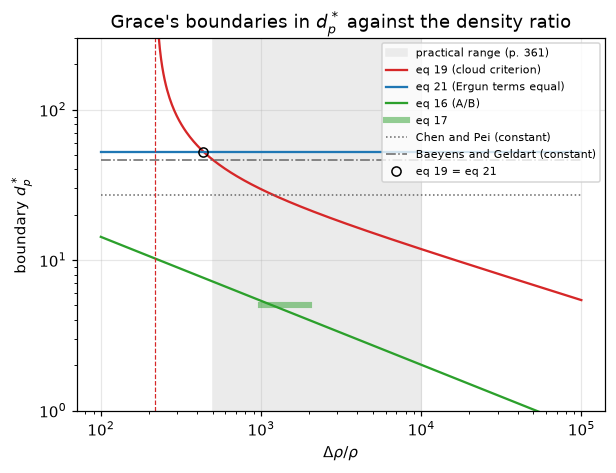

`find_roots` on $(b, 10^7)$ finds one crossing of eq 19 and eq 21, at $\Delta\rho/\rho$ = 437.1 (the quadratic of the published model agrees to 4e-16, bound 1e-12); with the printed 251, 219 and 53 it is 433.6, and with eq 19 and eq 21 both rebuilt from the rounding interval of the printed $C_1$, $C_2$ it runs from 436.6 to 437.7. All 4 of the 4 lie below 500, the exact crossing 12.6 % below 500. The crossing is exactly twice eq 19's $b$ (gap 1e-16, bound 1e-10), whatever $C_1$ is, so what could move it is the assumed $\epsilon_{mf}$ and $d_b/d_p$ of p. 361: it reaches 500 for $\epsilon_{mf}$ = 0.449 instead of 0.42, or $d_b$ = 114.4 $d_p$ instead of 100, and 500 is the low end of what Grace calls "of order 500 to $10^4$". Over 500 to $10^4$, eq 21 is 1.132 to 4.440 times eq 19 in $d_p^*$ (at the test particle 2.494, a factor 15.5 in $Ar$). Eq 19 meets the constant Chen-Pei 27 at $\Delta\rho/\rho$ = 1203 and the Baeyens-Geldart 46 at 505.

In [12]:
coef19, b19 = M["eq19_coef_derived"], M["eq19_b_derived"]
d21 = M["eq21_dstar_bd_pair"]
xx = np.geomspace(100, 1e5, 400)
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.axvspan(K["eq19_x_lo"], K["eq19_x_hi"], color="0.92", label="practical range (p. 361)")
xb = xx[xx > b19 * 1.0005]
ax.loglog(xb, [eq19(x, coef19, b19) for x in xb], "C3", label="eq 19 (cloud criterion)")
ax.loglog(xx, np.full_like(xx, d21), "C0", label="eq 21 (Ergun terms equal)")
ax.loglog(xx, [eq16(K, x) for x in xx], "C2", label="eq 16 (A/B)")
ax.plot([K["eq17_x_lo"], K["eq17_x_hi"]], [K["eq17_dstar"]] * 2, "C2", lw=4, alpha=0.5, label="eq 17")
for d0, lab, ls in ((K["chenpei_dstar"], "Chen and Pei", ":"), (K["bg_dstar"], "Baeyens and Geldart", "-.")):
    ax.loglog(xx, np.full_like(xx, d0), "0.4", ls=ls, lw=1, label=f"{lab} (constant)")
ax.plot(M["x_cross_19_21_exact"], d21, "ko", mfc="none", label="eq 19 = eq 21")
ax.axvline(b19, color="C3", lw=0.8, ls="--")
ax.set(xlabel=r"$\Delta\rho/\rho$", ylabel=r"boundary $d_p^*$", ylim=(1, 300),
       title="Grace's boundaries in $d_p^*$ against the density ratio")
ax.legend(fontsize=7, loc="upper right")
plt.show()
say("`find_roots` on $(b, 10^7)$ finds one crossing of eq 19 and eq 21, at $\\Delta\\rho/\\rho$ = <<x:.1f>> "
    "(the quadratic of the published model agrees to <<g:.0e>>, bound 1e-12); with the printed 251, 219 and 53 it "
    "is <<xp:.1f>>, and with eq 19 and eq 21 both rebuilt from the rounding interval of the printed $C_1$, $C_2$ it "
    "runs from <<xl:.1f>> to <<xh:.1f>>. All <<n:d>> of the 4 lie below 500, the exact crossing <<m:pct1>> below 500. "
    "The crossing is exactly twice eq 19's $b$ (gap <<gb:.0e>>, bound 1e-10), whatever $C_1$ is, so what could move it is the assumed "
    "$\\epsilon_{mf}$ and $d_b/d_p$ of p. 361: it reaches 500 for $\\epsilon_{mf}$ = <<ee:.3f>> instead of 0.42, or $d_b$ = "
    "<<dd:.1f>> $d_p$ instead of 100, and 500 is the low end of what Grace calls \"of order 500 to $10^4$\". Over 500 to $10^4$, eq 21 is <<r5:.3f>> to <<r4:.3f>> times eq 19 in $d_p^*$ (at the test "
    "particle <<rt:.3f>>, a factor <<at:.1f>> in $Ar$). Eq 19 meets the constant Chen-Pei 27 at "
    "$\\Delta\\rho/\\rho$ = <<xc:.0f>> and the Baeyens-Geldart 46 at <<xg:.0f>>.",
    x=M["x_cross_19_21_exact"], g=max(M["x_cross_closed_gap"], 1e-16), xp=M["x_cross_19_21_printed"],
    xl=min(M["x_cross_19_21_C_lo"], M["x_cross_19_21_C_hi"]), xh=max(M["x_cross_19_21_C_lo"], M["x_cross_19_21_C_hi"]),
    n=M["x_cross_n_below_500"], m=M["x_cross_19_21_margin_to_500"], r5=M["ratio_21_over_19_500"],
    gb=max(M["x_cross_minus_2b_gap"], 1e-16), ee=M["eps_mf_for_cross_500"], dd=M["db_over_dp_for_cross_500"],
    r4=M["ratio_21_over_19_1e4"], rt=M["ratio_21_over_19_T"], at=M["Ar_ratio_21_over_19_T"],
    xc=M["x_cross_19_chenpei27"], xg=M["x_cross_19_baeyensgeldart46"])

In micrometres for air at A1 and the glass of A3, beside the sizes Grace prints for
"most cases" (p. 357): C "less than about 20 µm", A "from 30-100 µm", B "from
100-800 µm", D "greater than about 1 mm".

In [13]:
say("C/A <<c1:.1f>> to <<c2:.1f>> µm (eq 15); A/B <<ab:.1f>> µm (eq 16); B/D <<b19:.1f>> µm by eq 19 and <<b21:.0f>> "
    "µm by eq 21. Eq 16 lands inside the A range (<<f1:d>> of 1), eq 19 inside the B range (<<f2:d>> of 1), and eq 21 "
    "beyond 1 mm (<<f3:d>> of 1).",
    c1=M["dpCA_lo_um_T"], c2=M["dpCA_hi_um_T"], ab=M["dpAB_um_T"], b19=M["eq19_dp_um_T"], b21=M["dpBD21_um_T"],
    f1=M["ab_T_inside_A_range"], f2=M["bd19_T_inside_B_range"], f3=M["bd21_T_above_D_size"])

C/A 15.3 to 24.7 µm (eq 15); A/B 88.4 µm (eq 16); B/D 477.2 µm by eq 19 and 1190 µm by eq 21. Eq 16 lands inside the A range (1 of 1), eq 19 inside the B range (1 of 1), and eq 21 beyond 1 mm (1 of 1).

### R6. The A/B boundary

Grace on eq 17: "Equation (17) can lead to serious errors in the transitional
$d_p^*$ or Ar values for" density ratios differing widely from 1000-2000.

In [14]:
say("Eq 16's $Ar$ form follows from its $d_p^*$ form: $101^3$ = <<c:,.0f>> (<<hc:.2f>> half-units of the printed "
    "1.03e6) and the exponent <<e:.3f>> (<<he:.2f>> half-units). Over 1000 to 2000, eq 16 gives $d_p^*$ <<d1:.3f>> to "
    "<<d2:.3f>> and $Ar$ <<a1:.1f>> to <<a2:.1f>>; eq 17's 5 and 125 lie inside (<<i1:d>> and <<i2:d>> of 1). "
    "Eq 17 over eq 16 is <<r1:.3f>> at $\\Delta\\rho/\\rho$ = 100 and <<r2:.3f>> at $10^4$. Eq 19 over eq 16 has "
    "its minimum <<mn:.3f>> at $\\Delta\\rho/\\rho$ = <<xm:.1f>> (root of the analytic derivative; the closed form "
    "agrees to <<gx:.0e>>, bound 1e-12), so under eqs 16 and 19 group B never vanishes for $x > b$. Eq 16 meets "
    "eq 21 only at $\\Delta\\rho/\\rho$ = <<x6:.3f>>.",
    c=M["eq16_Ar_coef"], hc=M["hu_eq16_Ar_coef"], e=M["eq16_Ar_exp"], he=M["hu_eq16_Ar_exp"],
    d1=M["eq16_dstar_2000"], d2=M["eq16_dstar_1000"], a1=M["eq16_Ar_2000"], a2=M["eq16_Ar_1000"],
    i1=M["eq17_dstar_inside"], i2=M["eq17_Ar_inside"], r1=M["ratio_17_over_16_100"], r2=M["ratio_17_over_16_1e4"],
    mn=M["min_ratio_19_16"], xm=M["x_min_ratio_19_16"], gx=max(M["x_min_closed_gap"], 1e-16), x6=M["x_cross_16_21"])

Eq 16's $Ar$ form follows from its $d_p^*$ form: $101^3$ = 1,030,301 (0.06 half-units of the printed 1.03e6) and the exponent 1.275 (0.00 half-units). Over 1000 to 2000, eq 16 gives $d_p^*$ 3.994 to 5.362 and $Ar$ 63.7 to 154.2; eq 17's 5 and 125 lie inside (1 and 1 of 1). Eq 17 over eq 16 is 0.350 at $\Delta\rho/\rho$ = 100 and 2.481 at $10^4$. Eq 19 over eq 16 has its minimum 5.390 at $\Delta\rho/\rho$ = 1808.1 (root of the analytic derivative; the closed form agrees to 1e-16, bound 1e-12), so under eqs 16 and 19 group B never vanishes for $x > b$. Eq 16 meets eq 21 only at $\Delta\rho/\rho$ = 4.653.

### R7. The C/A boundary: eq 15 from eq 14

In [15]:
show = CMP[CMP.group == "eq 15"][["item", "printed", "computed", "half-units"]]
display(plain(show))
say(r"$\Delta\rho$ cancels from eq 14 in $Ar$: the boundary from eq 14 solved for $d_p$ at twice the particle "
    r"density gives the same $d_p^*$ to <<g:.0e>> (an identity; bound 1e-12). At A1, <<n:d>> of the 4 printed eq 15 "
    r"numbers are roundings of the computed ones. Grace prints no air properties: the four printed numbers are all "
    r"roundings only for $\mu$ between <<lo:.3f>> and <<hi:.3f>> µPa s at A1's density; A1's <<mu:.3f>> lies inside "
    r"(<<f:d>> of 1), <<m:pct2>> from the nearer end. Which viscosity Grace used is not known.",
    g=max(M["ca_drho_gap"], 1e-16), n=M["eq15_within"], lo=M["mu_window_lo_uPas_at_rhoT"],
    hi=M["mu_window_hi_uPas_at_rhoT"], mu=M["mu_air_T"] * 1e6, f=M["mu_A1_inside_window"],
    m=M["mu_A1_window_margin"])

,item,printed,computed,half-units
0,"(d*)CA, F_H 8.8e-8 N",0.68,0.67606,0.788
1,"Ar_CA, F_H 8.8e-8 N",0.31,0.309,0.200
2,"(d*)CA, F_H 3.7e-7 N",1.1,1.0912,0.177
3,"Ar_CA, F_H 3.7e-7 N",1.3,1.2992,0.016


$\Delta\rho$ cancels from eq 14 in $Ar$: the boundary from eq 14 solved for $d_p$ at twice the particle density gives the same $d_p^*$ to 1e-16 (an identity; bound 1e-12). At A1, 4 of the 4 printed eq 15 numbers are roundings of the computed ones. Grace prints no air properties: the four printed numbers are all roundings only for $\mu$ between 18.189 and 18.408 µPa s at A1's density; A1's 18.364 lies inside (1 of 1), 0.24 % from the nearer end. Which viscosity Grace used is not known.

### R8. Table 2 and Richardson-Zaki's brackets

Eq 13 is written for liquid-solid suspensions; the page checks only its internal
consistency with Table 2, not Richardson and Zaki's original thresholds.

In [16]:
show = CMP[CMP.group.isin(["Table 2", "eq 13"])][["group", "item", "printed", "computed", "half-units"]]
display(plain(show))
say(r"The pieces of Table 2 join with jumps of <<j1:+.3f>> %, <<j2:+.3f>> % and <<j3:+.3f>> % at $d_p^*$ = 3.8, "
    r"7.58 and 227. <<n:d>> of the 7 printed $v_T^*$ range ends lie within a half-unit of the formula at their "
    r"$d_p^*$ end; the last, 91.7 at 3350, is <<v:.3f>>, <<h:.2f>> half-units away. With the printed $d_p^*$ given its half-unit too (v* at 3349.5 is <<v5:.4f>>), <<pw:d>> of the 7 "
    r"ends are within a half-unit. Row 1 "
    r"tends to Stokes' $d_p^{*2}/18$ (gap <<s:.0e>> at $d_p^*$ = 0.001, bound 1e-10). Each bracket of eq 13 names a "
    r"$d_p^*$ \"or\" a $v_T^*$; through Table 2 <<p:d>> of the 6 ends lie within a half-unit of their partner (<<qw:d>> of 6 with the partner's own half-unit) "
    r"($v_T^*$ at 2.7 is <<hv:.2f>> half-units from 0.37, $d_p^*$ at $v_T^*$ = 10 is <<hd:.2f>> from 44). $n$ is "
    r"continuous across the three brackets to <<n1:+.2f>> %, <<n2:+.2f>> % and <<n3:+.2f>> %, at $Re_t$ = <<t1:.3f>>, "
    r"<<t2:.3f>> and <<t3:.0f>>. At the test particle $v_T^*$ = <<vt:.4f>>, $v_T$ = <<vm:.4f>> m/s.",
    j1=100 * M["t2_jump_rel_3p8"], j2=100 * M["t2_jump_rel_7p58"], j3=100 * M["t2_jump_rel_227"],
    pw=M["t2_partner_ends_within"], qw=M["eq13_partner_ends_within"], v5=M["t2_v_at_3349p5"],
    n=M["t2_range_cells_within_half_unit"], v=M["t2_v_at_3350"], h=M["t2_halfunits_91p7"],
    s=max(M["stokes_limit_gap"], 1e-16), p=M["eq13_pair_ends_within_half_unit"], hv=M["eq13_halfunits_v_at_2p7"],
    hd=M["eq13_halfunits_d_at_v10"], n1=100 * M["eq13_n_jump_1p5"], n2=100 * M["eq13_n_jump_2p7"],
    n3=100 * M["eq13_n_jump_44"], t1=M["eq13_Ret_at_1p5"], t2=M["eq13_Ret_at_2p7"], t3=M["eq13_Ret_at_44"],
    vt=M["vTstar_T"], vm=M["vT_T_m_per_s"])

,group,item,printed,computed,half-units
0,Table 2,"v* range end, row 1 at 3.8",0.624,0.62437,0.744
1,Table 2,"v* range end, row 2 at 3.8",0.624,0.62445,0.890
2,Table 2,"v* range end, row 2 at 7.58",1.63,1.6347,0.945
3,Table 2,"v* range end, row 3 at 7.58",1.63,1.634,0.804
4,Table 2,"v* range end, row 3 at 227",28,28.075,0.150
5,Table 2,"v* range end, row 4 at 227",28,28.056,0.111
6,Table 2,"v* range end, row 4 at 3350",91.7,91.753,1.062
7,eq 13,v* at d* = 1.5,0.12,0.12267,0.534
8,eq 13,v* at d* = 2.7,0.37,0.36478,1.044
9,eq 13,v* at d* = 44,10,9.8722,0.256


The pieces of Table 2 join with jumps of +0.012 %, -0.043 % and -0.070 % at $d_p^*$ = 3.8, 7.58 and 227. 6 of the 7 printed $v_T^*$ range ends lie within a half-unit of the formula at their $d_p^*$ end; the last, 91.7 at 3350, is 91.753, 1.06 half-units away. With the printed $d_p^*$ given its half-unit too (v* at 3349.5 is 91.7485), 7 of the 7 ends are within a half-unit. Row 1 tends to Stokes' $d_p^{*2}/18$ (gap 6e-12 at $d_p^*$ = 0.001, bound 1e-10). Each bracket of eq 13 names a $d_p^*$ \"or\" a $v_T^*$; through Table 2 4 of the 6 ends lie within a half-unit of their partner (6 of 6 with the partner's own half-unit) ($v_T^*$ at 2.7 is 1.04 half-units from 0.37, $d_p^*$ at $v_T^*$ = 10 is 1.57 from 44). $n$ is continuous across the three brackets to -0.45 %, +0.11 % and +0.13 %, at $Re_t$ = 0.184, 0.985 and 434. At the test particle $v_T^*$ = 5.6037, $v_T$ = 3.8365 m/s.

### The map

The page's own skeleton of Fig 3, from the equations only: the band of eq 11 over the
six pairs, the terminal-velocity curve of Table 2, and the group boundaries for air
at A1 (eq 15) and for any gas (eqs 17 and 21), with eq 19 at the two ends of the
practical range. The reactor regions of Fig 3 have no equation behind them and are
not drawn.

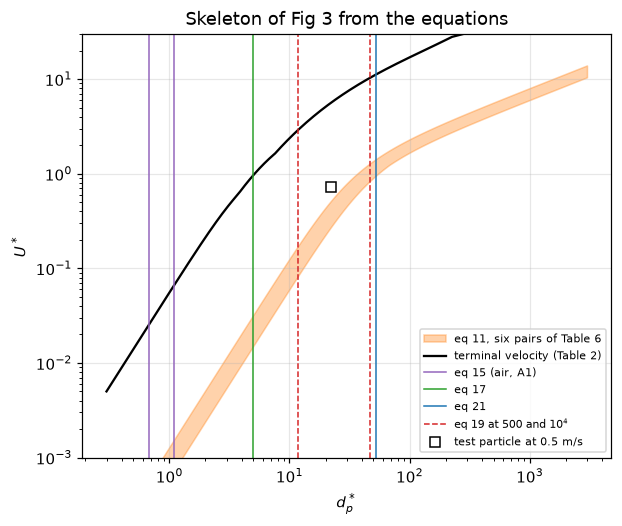

In [17]:
dd = np.geomspace(0.3, 3000, 400)
band = np.array([[umf_star(d, *pair(K, p)) for p in PAIRS] for d in dd])
fig, ax = plt.subplots(figsize=(6.2, 5.0))
ax.fill_between(dd, band.min(1), band.max(1), color="C1", alpha=0.35, label="eq 11, six pairs of Table 6")
ax.loglog(dd, [vt(K, d) for d in dd], "k", label="terminal velocity (Table 2)")
for d0, lab, st in ((M["dstarCA_lo_T"], "eq 15 (air, A1)", "C4"), (M["dstarCA_hi_T"], None, "C4"),
                    (K["eq17_dstar"], "eq 17", "C2"), (d21, "eq 21", "C0"),
                    (M["eq19_exact_500"], "eq 19 at 500 and $10^4$", "C3"), (M["eq19_exact_1e4"], None, "C3")):
    ax.axvline(d0, color=st, ls="--" if st == "C3" else "-", lw=1, label=lab)
ax.plot(M["dstar_T"], M["Ustar_T"], "ks", mfc="none", label="test particle at 0.5 m/s")
ax.set(xlabel=r"$d_p^*$", ylabel=r"$U^*$", ylim=(1e-3, 30), title="Skeleton of Fig 3 from the equations")
ax.legend(fontsize=7, loc="lower right")
plt.show()

## Validation

### V1. Each closed form against a general route

In [18]:
say("Eq 19 against eq 18 solved directly in $d_p^*$ at the test particle: <<a:.0e>>; against eq 18 in SI units "
    "solved for $d_p$ in micrometres: <<b:.0e>> (bound 1e-10 each). Eq 20 against the root of eq 10 at "
    "$Re_{mf} = 2C_1$: <<c:.0e>> (bound 1e-10). The crossing by `find_roots` against the quadratic: <<d:.0e>>; the "
    "minimum of eq 19 over eq 16 against its closed form: <<e:.0e>> (bound 1e-12 each).",
    a=max(M["eq19_direct_gap_T"], 1e-16), b=max(M["eq19_SI_gap_T"], 1e-16), c=max(M["eq20_root_gap"], 1e-16),
    d=max(M["x_cross_closed_gap"], 1e-16), e=max(M["x_min_closed_gap"], 1e-16))

Eq 19 against eq 18 solved directly in $d_p^*$ at the test particle: 1e-16; against eq 18 in SI units solved for $d_p$ in micrometres: 3e-16 (bound 1e-10 each). Eq 20 against the root of eq 10 at $Re_{mf} = 2C_1$: 2e-16 (bound 1e-10). The crossing by `find_roots` against the quadratic: 4e-16; the minimum of eq 19 over eq 16 against its closed form: 1e-16 (bound 1e-12 each).

### V2. Eq 18 depends on $d_p^*$ and $\Delta\rho/\rho$ only

Eq 18 in SI units is solved again with the viscosity doubled and $g$ = 9.0 m/s² at the
same density ratio; the $d_p^*$ it returns must equal eq 19's.

In [19]:
say("Relative difference: <<g:.0e>> (bound 1e-10), with $d_p$ itself moving from <<d1:.1f>> to <<d2:.1f>> µm.",
    g=max(M["v2_eq18_scaling_gap"], 1e-16), d1=M["eq19_dp_um_T"], d2=M["v2_dp_um_scaled"])

Relative difference: 6e-16 (bound 1e-10), with $d_p$ itself moving from 477.2 to 779.5 µm.

### V3. The check values

In [20]:
say("The page's functions reproduce all <<c:d>> check values of the second route, worst relative deviation "
    "<<w:.0e>> against a tolerance of 1e-11.",
    c=len(CHECK_DEV), w=max(max(abs(v) for v in CHECK_DEV.values()), 1e-16))

The page's functions reproduce all 118 check values of the second route, worst relative deviation 4e-12 against a tolerance of 1e-11.

## Finding

In [21]:
say("**The boundary numbers follow from the printed equations.** <<n:d>> of the <<t:d>> comparisons with a number "
    "Grace prints (Table 6's derived cells, eq 19's constants and limits, eq 21 and the p. 361 values, eq 15 at A1, "
    "eq 16's $Ar$ form) lie within a half-unit of the last printed digit when recomputed from the constants he "
    "states for them, taking those constants as exact (eq 15's four with the page's air viscosity). The closest is "
    "Richardson's 53, computed <<r:.3f>>, <<m:.3f>> of a half-unit from 53; the rounding of his $C_1$, $C_2$ "
    "carries it from <<rl:.2f>> to <<rh:.2f>>, across 52.5, so that 53 cannot be decided. Eq 15 needs an air viscosity the paper "
    "does not print; it holds for $\\mu$ from <<lo:.2f>> to <<hi:.2f>> µPa s. Eq 19's 219 fixes the bubble "
    "coefficient 0.711 (with $1/\\sqrt2$ it would be <<b2:.1f>>). In the supporting tables, <<t2:d>> of 7 Table 2 range ends and "
    "<<e13:d>> of 6 eq 13 bracket ends lie within a half-unit of the formula at the printed partner taken exactly; "
    "with the partner given its own half-unit, <<t2p:d>> of 7 and <<e13p:d>> of 6.\n\n"
    "**The two B/D criteria part.** Built on eq 10 with the same $C_1$, $C_2$, eq 19 and eq 21 cross once, at "
    "$\\Delta\\rho/\\rho$ = <<x:.1f>> (<<xp:.1f>> from the printed constants), exactly twice eq 19's constant $b$, "
    "<<mg:pct1>> below 500 and at the low end of what Grace calls \"of order 500 to $10^4$\"; it stays below 500 "
    "over the rounding of his constants. It reaches 500 for $\\epsilon_{mf}$ = <<ee:.3f>> instead of his 0.42, or "
    "$d_b$ = <<dd:.0f>> $d_p$ instead of 100. Over 500 to $10^4$ the criteria differ by a factor <<r5:.2f>> to <<r4:.2f>> in $d_p^*$; for glass in air at A1, <<b19:.0f>> µm "
    "against <<b21:.0f>> µm. Grace recommends eq 21; the page measures the gap and does not decide between them.",
    n=M["boundary_numbers_within"], t=M["boundary_numbers_within_of"], m=M["boundary_numbers_max_halfunits"],
    lo=M["mu_window_lo_uPas_at_rhoT"], hi=M["mu_window_hi_uPas_at_rhoT"], b2=M["eq19_b_one_over_sqrt2"],
    t2=M["t2_range_cells_within_half_unit"], e13=M["eq13_pair_ends_within_half_unit"],
    t2p=M["t2_partner_ends_within"], e13p=M["eq13_partner_ends_within"], r=M["t6_richardson_dBD"],
    rl=M["dBD_richardson_lo"], rh=M["dBD_richardson_hi"], ee=M["eps_mf_for_cross_500"], dd=M["db_over_dp_for_cross_500"],
    x=M["x_cross_19_21_exact"], xp=M["x_cross_19_21_printed"], mg=M["x_cross_19_21_margin_to_500"],
    r5=M["ratio_21_over_19_500"], r4=M["ratio_21_over_19_1e4"], b19=M["eq19_dp_um_T"], b21=M["dpBD21_um_T"])

**The boundary numbers follow from the printed equations.** 36 of the 36 comparisons with a number Grace prints (Table 6's derived cells, eq 19's constants and limits, eq 21 and the p. 361 values, eq 15 at A1, eq 16's $Ar$ form) lie within a half-unit of the last printed digit when recomputed from the constants he states for them, taking those constants as exact (eq 15's four with the page's air viscosity). The closest is Richardson's 53, computed 52.507, 0.985 of a half-unit from 53; the rounding of his $C_1$, $C_2$ carries it from 52.42 to 52.60, across 52.5, so that 53 cannot be decided. Eq 15 needs an air viscosity the paper does not print; it holds for $\mu$ from 18.19 to 18.41 µPa s. Eq 19's 219 fixes the bubble coefficient 0.711 (with $1/\sqrt2$ it would be 216.2). In the supporting tables, 6 of 7 Table 2 range ends and 4 of 6 eq 13 bracket ends lie within a half-unit of the formula at the printed partner taken exactly; with the partner given its own half-unit, 7 of 7 and 6 of 6.

**The two B/D criteria part.** Built on eq 10 with the same $C_1$, $C_2$, eq 19 and eq 21 cross once, at $\Delta\rho/\rho$ = 437.1 (433.6 from the printed constants), exactly twice eq 19's constant $b$, 12.6 % below 500 and at the low end of what Grace calls "of order 500 to $10^4$"; it stays below 500 over the rounding of his constants. It reaches 500 for $\epsilon_{mf}$ = 0.449 instead of his 0.42, or $d_b$ = 114 $d_p$ instead of 100. Over 500 to $10^4$ the criteria differ by a factor 1.13 to 4.44 in $d_p^*$; for glass in air at A1, 477 µm against 1190 µm. Grace recommends eq 21; the page measures the gap and does not decide between them.

## What pymrm adds

Nothing to the correlations: the page is algebra on printed equations and calls no
pymrm operator; nothing is discretised or solved as a differential equation. pymrm
contributes `pymrm.checks.find_roots`, which solves eq 18 directly (in $d_p^*$ and in
SI units), shows that eq 18 has no root below $\Delta\rho/\rho = b$, finds the
crossings of eq 19 with eq 21 and with the constant B/D values, the crossing of eq 16
with eq 21, the minimum of eq 19 over eq 16 as a root of its derivative, and inverts
Table 2, each time raising unless exactly one root is found. What the page adds to the
paper is the test of each printed number in half-units, the measured gap between the
two B/D criteria, and the viscosity window that eq 15 implies.

## Reuse

- `air`, `re_mf`, `umf_star`, `eq19`, `eq20`, `eq16`, `ca_boundary` and `vt` take the
  dictionary `K`; replace the A1 entries by another gas to place a powder in another
  gas, temperature or pressure. Below $\Delta\rho/\rho = b$ eq 19 has no group D.
- Choosing eq 19 or eq 21 for B/D is a choice of a boundary up to the factor in R5;
  state which one is used. The constant B/D values of Chen and Pei and of Baeyens and
  Geldart correspond to single density ratios of eq 19 (R5).
- Eq 17 is eq 16 over 1000 to 2000 only; use eq 16 elsewhere (R6).
- Related pages: [A1.7](../A1.7-geldart-classification/) (Geldart's dimensional
  groups), [A1.8](../A1.8-gas-solid-drag-closures/) (drag closures),
  [E1.1](../E1.1-two-phase-theory/) and [E2.1](../E2.1-kunii-levenspiel-bubbling-bed/)
  (bubbling-bed models).

### The break table

Every non-structural number registered below has a row that moves it. Each row
mistypes one printed constant by 10 % (or changes one assumption, or one reading of
an equation) and reruns the whole study; the claims it fails are counted. A row
records only the claims it returned a number for; a row under which the study
raises is listed as a crash and catches nothing. The structural claims are the
identities of R1, R3 at $Re_{mf} = 2C_1$, the closed forms against their own
general routes (eq 19, the crossing, the minimum, eq 14 in $Ar$), the scaling of V2,
the absence of a root of eq 18 below $b$, the count of R3's overpredictions (12 of 12
for any positive $C_1$, $C_2$) and the totals of the counts: no changed constant can
move them.

In [22]:
RTOL = 1e-6
STRUCTURAL = {
    "r1_identity_gap": "eqs 5 to 9 and N_D are identities in d* and U*",
    "ratio11_at_Remf_2C1_gap": "at Re_mf = 2 C1, eq 11a / eq 11 = 2 and eq 11b / eq 11 = sqrt 2 for any C1, C2",
    "eq19_direct_gap_T": "eq 19's closed form is the exact root of eq 18 for any constants; bound: find_roots xtol",
    "eq19_SI_gap_T": "the same in SI units, solved in micrometres",
    "v2_eq18_scaling_gap": "eq 18 depends on d* and drho/rho only, for any mu and g",
    "x_cross_closed_gap": "the quadratic is the exact crossing of eq 19 with a constant",
    "x_cross_minus_2b_gap": "eq 19 and eq 21 are built on the same C1, C2, so d0^3/coef^3 = 2/b and the crossing is exactly 2b, "
                            "whatever C1 is",
    "x_min_closed_gap": "the closed form is the exact root of the derivative",
    "ca_drho_gap": "drho cancels from eq 14 in Ar",
    "err11_n_over": "Re_mf = C2 Ar / (sqrt(C1^2 + C2 Ar) + C1) lies below C2 Ar / (2 C1) and below sqrt(C2 Ar) "
                    "for any positive C1, C2, Ar, so both limits overpredict for every pair",
    "eq18_roots_below_b": "for x <= b eq 18 has no root in d* (published model, E11)"}
BOUNDS = {"r1_identity_gap": (1e-12, "identity"), "ratio11_at_Remf_2C1_gap": (1e-12, "identity"),
          "eq19_direct_gap_T": (1e-10, "tolerance"), "eq19_SI_gap_T": (1e-10, "tolerance"),
          "v2_eq18_scaling_gap": (1e-10, "tolerance"), "x_cross_closed_gap": (1e-12, "tolerance"), "x_cross_minus_2b_gap": (1e-10, "tolerance"),
          "x_min_closed_gap": (1e-12, "tolerance"), "ca_drho_gap": (1e-12, "identity"),
          "eq20_root_gap": (1e-10, "tolerance"), "stokes_limit_gap": (1e-10, "theory")}
NOTES = {"eq20_root_gap": "eq 20 printed as 2 (C1^2/C2)^(1/3) against the root of eq 10 at the printed Re_mf = 2 C1",
         "stokes_limit_gap": "row 1 of Table 2 against Stokes' v* = d*^2/18 at d* = 0.001; the next term is 5.6e-12"}
# Count margins: the inputs are exact printed numbers, so a margin only needs to clear
# floating-point noise (about 1e-15); 1e-4 of a half-unit (or of the compared value) is
# chosen. The smallest margins are stated in the prose: the eq 21 rounding intervals
# end 0.04 in d* from 52.5, and A1's viscosity sits 0.24 % inside the eq 15 window
# (an assumed viscosity: that margin is its own claim, mu_A1_window_margin).
COUNT_MIN = 1e-4
EXACT = {"err11a_worst_pair", "err11b_worst_pair"}
INFO = {"boundary_numbers_within_of", "t6_cells_rounding_to_print_of", "eq15_within_of",
        "t2_range_cells_within_half_unit_of", "eq13_pair_ends_within_half_unit_of",
        "t2_partner_ends_within_of", "eq13_partner_ends_within_of"}


# printed as the identity's own values (2 and sqrt 2); their departure is the claim ratio11_at_Remf_2C1_gap
UNREGISTERED = {"ratio11a_at_dBD", "ratio11b_at_dBD"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin") or name in UNREGISTERED:
            continue
        if name in BOUNDS:
            mx, basis = BOUNDS[name]
            claims.bound(name, v, max=mx, basis=basis, structural=name in STRUCTURAL,
                         note=STRUCTURAL.get(name) or NOTES.get(name))
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in INFO:
            claims.exact(name, v, structural=True, note="number of printed entries compared")
        elif name + "__margin" in M:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNT_MIN)
        elif name in EXACT:
            claims.exact(name, v)
        elif name.startswith("hu_") or name.endswith("_halfunits"):
            claims.value(name, v, rtol=RTOL, atol=1e-6)
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

In [23]:
def mistyped(name, factor=1.1):
    v = K[name] * factor
    return f"{name} {PRINTED[name]} -> {v:.6g}", K | {name: v}


def set_to(name, v, why=""):
    old = PRINTED.get(name, f"{K[name]:g}")
    return f"{name} {old} -> {v:.6g}{why}", K | {name: v}


mu18 = 1.8e-5 / (air(K)["mu"])
DEFECTS = [mistyped(k, 0.9 if k == "t2_c4_1" else 1.1) for k in PRINTED] + [
    set_to("eq18_ub_coef", 1 / math.sqrt(2), " (Geldart's 1/sqrt 2)"),
    set_to("eq18_db_over_dp", 50.0), set_to("eq18_eps_mf", 0.45),
    ("Wen-Yu C1, C2 in eq 19 and eq 21", K | {"eq18_C1": K["t6_wenyu_C1"], "eq18_C2": K["t6_wenyu_C2"]}),
    set_to("eq20_prefactor", 1.0, " (eq 20 without the factor 2)"),
    set_to("t2_c1_a8", 1.6451e-6, " (digits transposed)"),
    set_to("eq16_exp", -0.43),
    ("air viscosity -> 18.0 uPa s", K | {"A_mu_factor": mu18}),
    set_to("eq14_K", 1e-1),
    set_to("eq15_T_K", 293.0, " (air temperature)"),
    set_to("A_g", 9.81), set_to("A_rho_p", 2600.0), set_to("A_dp_um", 550.0), set_to("A_U", 0.55),
    set_to("A_x_wide", 150.0), set_to("A_M_air", 0.029), set_to("A_S", 120.0),
    set_to("A_rho_p", 1000.0, " (a light test particle)"),
    set_to("t6_wenyu_C1", 25.7, " (Richardson's C1 read into Wen and Yu's row)"),
]
CONTROLS = [("control: clean rerun", K), ("control: Sutherland reference written as 1.716e-5 x 1.0", K | {"A_mu_factor": 1.0})]
RAN, CRASH = {}, {}
for row, k_ in CONTROLS + DEFECTS:
    try:
        RAN[row] = study(k_)
    except (ValueError, ZeroDivisionError) as err:
        CRASH[row] = str(err)
claims.define_rows(list(RAN))   # a crashed row catches nothing, so it is listed apart, not declared
BREAK = []
for row, Mb in RAN.items():
    for name in claims.metrics:
        v = Mb.get(name)
        if v is None or (isinstance(v, float) and not math.isfinite(v)):
            continue
        BREAK.append((row, name, claims.breaks(row, name, v)))

In [24]:
# The break table: one line per row, with the claims it fails.
by_row = {r_: [] for r_, _ in CONTROLS + DEFECTS}
for r_, m_, c_ in BREAK:
    by_row[r_].append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<62} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:62]:<62} {sum(cs):13d}" + ("   (crash)" if r_ in CRASH else ""))
print(f"rows that crash: {', '.join(f'{r_}: {e_}' for r_, e_ in CRASH.items()) or 'none'}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_struct = sorted(k_ for k_ in claims.metrics if claims.metrics[k_].get("structural"))
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and k_ not in _struct)
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"{len(_struct)} structural: {', '.join(_struct)}; open: {', '.join(_open) or 'none'}")

injected defect                                                claims failed
control: clean rerun                                                       0
control: Sutherland reference written as 1.716e-5 x 1.0                    0
t6_wenyu_C1 33.7 -> 37.07                                                 12
t6_wenyu_C2 0.0408 -> 0.04488                                             14
t6_wenyu_half_ratio 6.1e-4 -> 0.000671                                     3
t6_wenyu_sqrtC2 0.202 -> 0.2222                                            3
t6_wenyu_dBD 61 -> 67.1                                                    3
t6_richardson_C1 25.7 -> 28.27                                            13
t6_richardson_C2 0.0365 -> 0.04015                                        16
t6_richardson_half_ratio 7.1e-4 -> 0.000781                                3
t6_richardson_sqrtC2 0.191 -> 0.2101                                       3
t6_richardson_dBD 53 -> 58.3                                               3

In [25]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for E2.3:
  rho_air_T                          = 1.1842           value  rtol 1e-06
  mu_air_T                           = 1.8364e-05       value  rtol 1e-06
  drho_over_rho_T                    = 2110.1           value  rtol 1e-06
  dstar_T                            = 22.074           value  rtol 1e-06
  Ustar_T                            = 0.73032          value  rtol 1e-06
  Ar_T                               = 10756            value  rtol 1e-06
  Re_T                               = 16.121           value  rtol 1e-06
  Fr_T                               = 0.024163         value  rtol 1e-06
  CD_T                               = 55.182           value  rtol 1e-06
  M_T                                = 0.38952          value  rtol 1e-06
  ND_T                               = 14341            value  rtol 1e-06
  r1_identity_gap                    = (here 2.7e-15)   bound  bound <= 1e-12 [identity]
  t6_wenyu_half_ratio                = 0.00060534       value  rtol 1e-06
  t6_w